# Extension — A hedge ratio that moves with a Kalman filter

Optional extension "Dynamic hedge ratio with a Kalman filter". Phase 2 failed out-of-sample because the
fixed hedge ratio β = 0.388 stopped fitting the prices, so I re-ran the frozen signal on a spread whose β
is re-estimated every day with a Kalman filter, using only the past.

**Result**
- The filter's β stays between 0.10 and 0.63 and never becomes negative. It is around 0.30 until 2023 and
  climbs to 0.62 by October 2026, so it does follow the 2024–2026 move of KO against PEP.
- In-sample the signal gets worse. The Sharpe ratio is 0.15 (t-stat 0.62), against 0.42 for the frozen
  strategy on the same days, and all of its in-sample gain comes from seven months of the 2008 crisis.
  Trades are twice as many (191 against 94) and much shorter (9 days against 32).
- Out-of-sample the loss is smaller (Sharpe −0.18 against −0.53, and −1.3% against −16.4% in 2025), but it
  is still a loss and neither number is far from zero.
- **So a moving β limits the damage of the 2024–2026 break but does not give the strategy an edge.** The
  slowest filter of the sensitivity check does best in both periods, but I saw that after computing it,
  so I do not treat it as a result.

All of this was done after the single out-of-sample run of Phase 2, so 2019–2026 is not a fresh test here.
Terms are in the README glossary.

## 1. Set-up and data

Same prices as Phase 2 and 3, 2000–2026. First I re-run the frozen Phase 2 strategy (threshold 1.5,
window 60, exit 0, β 0.388372) unchanged, as the benchmark.

In [1]:
import logging

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from pairs.backtest import run_zscore_strategy, summarize
from pairs.config import KALMAN_RULES, PAIR, PHASE2_STRATEGY, Settings
from pairs.data import load_pair_prices
from pairs.explore import select_until
from pairs.kalman import kalman_hedge, run_kalman_strategy
from pairs.logging_setup import configure_logging
from pairs.plots import equity_figure, finish_figure, save_figure
from pairs.spread import fit_hedge_ratio
from pairs.stability import rolling_hedge_ratio
from pairs.trials import count_trials, log_trial

configure_logging(logging.WARNING)  # notebook output: tables and charts only, no progress logs
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
SOURCE = (
    "Source: Yahoo Finance adjusted close, 3 Jan 2000 - 9 Oct 2026."
    " Shaded: out-of-sample (after the single run of Phase 2)."
)
A, B, PAIR_NAME, S, K = (
    PAIR.ticker_a,
    PAIR.ticker_b,
    f"{PAIR.ticker_a}/{PAIR.ticker_b}",
    PHASE2_STRATEGY,
    KALMAN_RULES,
)

prices = load_pair_prices(PAIR, settings.data_dir, PAIR.end)
is_prices = select_until(prices, PAIR.in_sample_end)
ols = fit_hedge_ratio(prices, A, B, PAIR.in_sample_end)
assert abs(ols.beta - S.beta) < 1e-6  # the frozen β
is_start = is_prices.index[249]  # Phase 2 first day
oos_start = prices.index[prices.index > pd.Timestamp(PAIR.in_sample_end)][0]
phase2 = {
    "in-sample": run_zscore_strategy(
        is_prices, A, B, S.beta, S.entry, S.window, is_start, S.exit
    ).loc[is_start:],
    "out-of-sample": run_zscore_strategy(
        prices, A, B, S.beta, S.entry, S.window, oos_start, S.exit
    ).loc[oos_start:],
}
pd.DataFrame({n: summarize(r["ret"], r["position"]) for n, r in phase2.items()}).loc[
    ["sharpe", "ann_return", "n_trades"]
].round(3)

,in-sample,out-of-sample
sharpe,0.351,-0.534
ann_return,0.024,-0.038
n_trades,94.000,36.000


## 2. Why a Kalman filter, and the rules

In Phase 2 the out-of-sample loss came from the spread KO − 0.388 × PEP drifting away for years, and in
Phase 3 the rolling hedge ratio moved a lot (−0.07 to 0.75 inside 2000–2018, −0.23 in 2025). A fixed β
estimated once on 2000–2018 cannot follow that. The natural fix is a β that is re-estimated every day using
only the past. The Kalman filter does this. It treats the intercept α and the hedge ratio β as numbers that
move a little each day (a random walk), and every day it updates them with the new prices, giving more
weight to the new data when its estimate is uncertain.

I fixed the rules in `src/pairs/config.py` (`KalmanRules`) before running the filter on the data:

- speed of β: δ = 1e-4, the usual textbook value (E. Chan, *Algorithmic Trading*, 2013), not tuned.
  δ = 1e-5 (slower) and 1e-3 (faster) are run only as sensitivity;
- start: α and β from an OLS on the year 2000 only; the filter runs from the first day of 2001;
- noise of KO around α + β × PEP: the variance of the residuals of the Phase 2 OLS (2000–2018);
- spread of day t = KO − α − β × PEP with α and β estimated with data up to t−1;
- same z-score and thresholds as the frozen strategy (window 60, entry 1.5, exit 0);
- the β of a trade is the one of the day it opens and stays fixed until it closes, so the shares do not
  change every day. β is free to become negative (then the trade buys or sells both stocks together);
- no transaction costs, so the numbers compare with Phase 2.

This is an analysis done after the single out-of-sample run of Phase 2: I already knew that 2019–2026 went
badly and why, so 2019–2026 is not a fresh test here. I wrote my guess before computing: the filter
should cut the 2024–2026 loss, but it can also absorb part of the mean reversion I want to trade, so I
expected an in-sample Sharpe below 0.35 (about 0.1–0.2). 6 backtests go to the trial log.

## 3. The hedge ratio of the filter

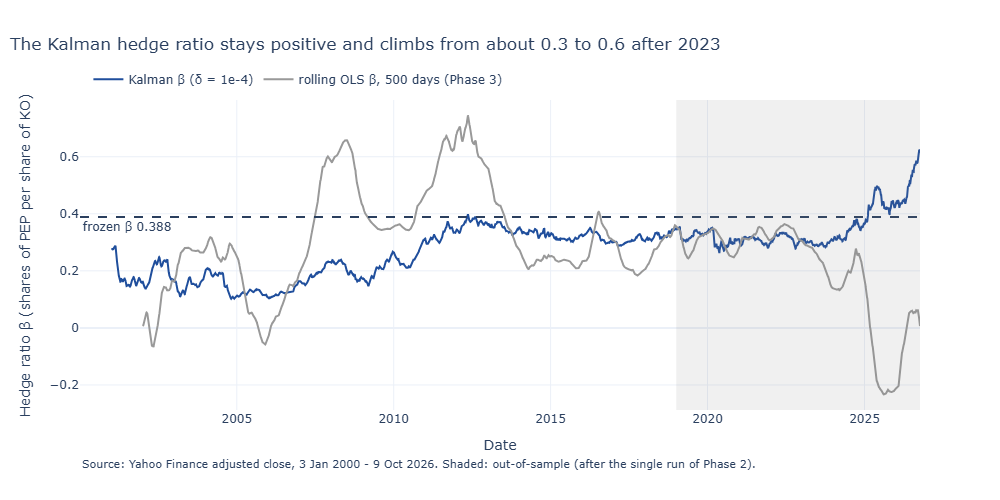

init alpha 7.602, beta 0.276; observation sd 2.251 dollars


Date,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean Kalman β,0.19,0.2,0.15,0.16,0.12,0.13,0.19,0.2,0.2,0.25,...,0.3,0.32,0.33,0.3,0.31,0.31,0.3,0.34,0.43,0.5


In [2]:
init = fit_hedge_ratio(prices, A, B, K.init_end)
residual = is_prices[A] - ols.alpha - ols.beta * is_prices[B]
obs_var = float(residual.var())
run_prices = prices.loc[prices.index > pd.Timestamp(K.init_end)]
filters = {
    d: kalman_hedge(run_prices, A, B, d, obs_var, init.alpha, init.beta)
    for d in (K.delta, *K.sensitivity_deltas)
}
filt = filters[K.delta]
rolling = rolling_hedge_ratio(prices, A, B, 500)

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=filt.index, y=filt["beta"], name="Kalman β (δ = 1e-4)", line={"color": "#1f4e9c"})
)
fig.add_trace(
    go.Scatter(
        x=rolling.index,
        y=rolling,
        name="rolling OLS β, 500 days (Phase 3)",
        line={"color": "#999999"},
    )
)
fig.add_hline(
    y=S.beta, line_dash="dash", annotation_text="frozen β 0.388", annotation_position="bottom left"
)
fig.add_vrect(x0=oos_start, x1=prices.index[-1], fillcolor="grey", opacity=0.12, line_width=0)
finish_figure(
    fig,
    "The Kalman hedge ratio stays positive and climbs from about 0.3 to 0.6 after 2023",
    "Date",
    "Hedge ratio β (shares of PEP per share of KO)",
    SOURCE,
)
save_figure(fig, "06_kalman_beta", figures_dir)
fig.show()
beta_year = filt["beta"].groupby(filt.index.year).mean()
print(
    f"init alpha {init.alpha:.3f}, beta {init.beta:.3f}; observation sd {obs_var**0.5:.3f} dollars"
)
beta_year.round(2).to_frame("mean Kalman β").T

The filter starts from the OLS on 2000 (α 7.60 dollars, β 0.276) and the noise of KO around the line
has a standard deviation of 2.25 dollars. Its β is low in the first decade (yearly means 0.12–0.20), around
0.30 from 2017 to 2023, then 0.43 in 2025 and 0.50 in 2026.

I expected it to go negative in 2025 like the 500-day rolling OLS of Phase 3 (the grey line), but it never
does: its lowest value is 0.10, in 2004. The difference is that the filter also moves the intercept α, and
with δ = 1e-4 β can only change slowly, so probably part of the drift goes into α instead of β. So the case
I worried about in section 2 (trades that buy or sell both stocks together) does not happen.

## 4. Backtests: Kalman spread against the frozen strategy

In [3]:
kal_start = filt.index[S.window - 1]  # first day with a full 60-day z-score of the Kalman spread
runs, rows = {}, {}
for d, f in filters.items():
    for sample, px, start in (
        ("in-sample", select_until(run_prices, PAIR.in_sample_end), kal_start),
        ("out-of-sample", run_prices, oos_start),
    ):
        run = run_kalman_strategy(px, f, A, B, S.entry, S.window, start, S.exit).loc[start:]
        stats = summarize(run["ret"], run["position"])
        log_trial(
            trials_db,
            "ext-kalman",
            PAIR_NAME,
            sample,
            (run.index[0].date(), run.index[-1].date()),
            {"delta": d, "entry": S.entry, "window": S.window, "exit": S.exit},
            stats,
            "main" if d == K.delta else "sensitivity on delta",
        )
        runs[(d, sample)], rows[(f"Kalman δ={d:g}", sample)] = run, stats
same_days = phase2["in-sample"].loc[kal_start:]
rows[("Phase 2 frozen", "in-sample")] = summarize(
    phase2["in-sample"]["ret"], phase2["in-sample"]["position"]
)
rows[("Phase 2 frozen, same days as Kalman", "in-sample")] = summarize(
    same_days["ret"], same_days["position"]
)
rows[("Phase 2 frozen", "out-of-sample")] = summarize(
    phase2["out-of-sample"]["ret"], phase2["out-of-sample"]["position"]
)
table = pd.DataFrame(rows).T[
    ["sharpe", "t_stat", "ann_return", "ann_vol", "max_drawdown", "n_trades", "avg_days_per_trade"]
]
table.sort_index().round(3)

sharpe  t_stat  ann_return  \
Kalman δ=0.0001                     in-sample       0.147   0.618       0.010   
                                    out-of-sample  -0.178  -0.495      -0.009   
Kalman δ=0.001                      in-sample      -0.134  -0.564      -0.008   
                                    out-of-sample  -0.072  -0.202      -0.003   
Kalman δ=1e-05                      in-sample       0.398   1.675       0.029   
                                    out-of-sample   0.030   0.084       0.002   
Phase 2 frozen                      in-sample       0.351   1.490       0.024   
                                    out-of-sample  -0.534  -1.486      -0.038   
Phase 2 frozen, same days as Kalman in-sample       0.416   1.751       0.028   

                                                   ann_vol  max_drawdown  \
Kalman δ=0.0001                     in-sample        0.068        -0.203   
                                    out-of-sample    0.049        -0.195   
Kalman δ=0.001                      in-sample        0.061        -0.307   
                                    out-of-sample    0.043        -0.139   
Kalman δ=1e-05                      in-sample        0.073        -0.166   
                                    out-of-sample    0.054        -0.208   
Phase 2 frozen                      in-sample        0.069        -0.144   
                                    out-of-sample    0.072        -0.318   
Phase 2 frozen, same days as Kalman in-sample        0.068        -0.144   

                                                   n_trades  \
Kalman δ=0.0001                     in-sample         191.0   
                                    out-of-sample     132.0   
Kalman δ=0.001                      in-sample         286.0   
                                    out-of-sample     168.0   
Kalman δ=1e-05                      in-sample         132.0   
                                    out-of-sample      84.0   
Phase 2 frozen                      in-sample          94.0   
                                    out-of-sample      36.0   
Phase 2 frozen, same days as Kalman in-sample          94.0   

                                                   avg_days_per_trade  
Kalman δ=0.0001                     in-sample                   9.199  
                                    out-of-sample               4.379  
Kalman δ=0.001                      in-sample                   4.584  
                                    out-of-sample               2.446  
Kalman δ=1e-05                      in-sample                  17.371  
                                    out-of-sample               9.714  
Phase 2 frozen                      in-sample                  32.043  
                                    out-of-sample              42.167  
Phase 2 frozen, same days as Kalman in-sample                  31.777

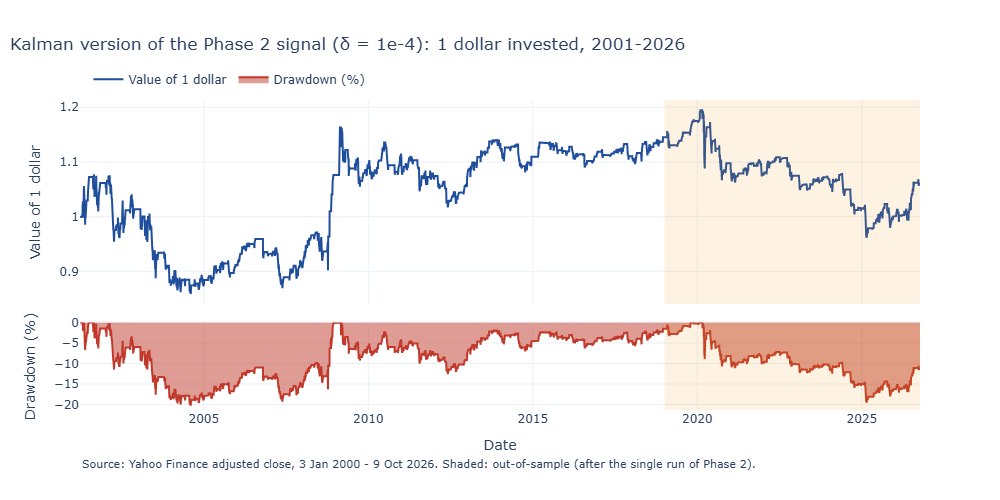

in-sample sum of daily returns 17.6%, of which Sep 2008 - Mar 2009 18.5%


Date,2019,2020,2021,2022,2023,2024,2025,2026
Kalman,2.6,-6.4,-1.7,-0.3,-0.5,-5.1,-1.3,5.9
Phase 2 frozen,0.3,5.2,-2.4,-6.1,-0.7,-0.9,-16.4,-8.7


In [4]:
main = pd.concat([runs[(K.delta, "in-sample")]["ret"], runs[(K.delta, "out-of-sample")]["ret"]])
fig = equity_figure(
    main,
    "Kalman version of the Phase 2 signal (δ = 1e-4): 1 dollar invested, 2001-2026",
    SOURCE,
    oos_start,
)
save_figure(fig, "06_kalman_equity", figures_dir)
fig.show()
by_year = pd.DataFrame(
    {
        "Kalman": main.groupby(main.index.year).sum(),
        "Phase 2 frozen": pd.concat([phase2["in-sample"]["ret"], phase2["out-of-sample"]["ret"]])
        .groupby(lambda t: t.year)
        .sum(),
    }
).loc[2019:]
is_ret = runs[(K.delta, "in-sample")]["ret"]
crisis = is_ret.loc["2008-09":"2009-03"].sum()
print(
    f"in-sample sum of daily returns {is_ret.sum():.1%}, of which Sep 2008 - Mar 2009 {crisis:.1%}"
)
(100 * by_year).round(1).T  # sum of daily returns in each year, %

The Kalman version starts trading about three months later than Phase 2 (the filter starts in 2001 and the
z-score needs 60 days), so I compare it with the frozen strategy on the same days: 0.42 in-sample, a bit
higher than the 0.35 of the full period.

In-sample the Kalman spread earns less (Sharpe 0.15 against 0.42) and trades much more often, with shorter
trades. The chart also shows that the in-sample gain is one jump in the 2008 crisis: from September 2008
to March 2009 the daily returns add up to 18.5%, more than the 17.6% of the whole in-sample period, so in
the other years the Kalman version earned nothing. My explanation for the lower Sharpe: the slow waves of the spread are exactly what the frozen strategy bets on, and a β
that adapts every day removes part of them from the spread. What is left is mostly short noise around a
moving line.

Out-of-sample the picture changes. The frozen strategy lost 16.4% in 2025 and 8.7% in 2026, when KO kept
gaining on PEP. The Kalman version lost only 1.3% in 2025 and gained 5.9% in 2026, because its β had moved
up. But it lost in other years (−6.4% in 2020, −5.1% in 2024), so over the whole period it is still
negative (Sharpe −0.18, t-stat −0.50) and its worst drawdown is −19.5% against −31.8%. My guess written in
section 2 was right on both points: a smaller loss in 2024–2026 and an in-sample Sharpe of about 0.15.

## 5. How much depends on δ

The two sensitivity filters move in a clear direction. The fast one (δ = 1e-3) trades 286 times in-sample,
4.6 days per trade, and loses in both periods (−0.13 and −0.07). The slow one (δ = 1e-5) trades 132 times
and has the best numbers of the table: 0.40 in-sample and 0.03 out-of-sample.

It would be easy to pick δ = 1e-5 now, but I chose δ = 1e-4 before computing and I saw the other two only
after the out-of-sample period, so picking the best of three would be fitting the past. What the pattern
does say is consistent with section 4: the slower the filter, the more of the slow deviations it leaves in
the spread, and those deviations are where the in-sample profit was. Following the drift of β and betting
on the spread coming back are in conflict, because both use the same slow moves.

None of these runs pays transaction costs. The Kalman version trades two to three times more than Phase 2,
so with costs its numbers would get worse than those of the frozen strategy.

## 6. Conclusion

A Kalman hedge ratio is the natural answer to the failure of Phase 2, and it does what it should: it
follows the change in the KO/PEP relationship and avoids most of the 2025–2026 loss. But it pays for this
in-sample, where the Sharpe drops from 0.42 to 0.15 on the same days, and out-of-sample it is still not
profitable. On these two stocks I find no evidence that a moving β turns the signal into a strategy with
an edge. The result depends a lot on δ, and the only value I can report fairly is the one fixed before
computing.

The 6 backtests of this notebook are in the trial log (phase "ext-kalman"). The cell below checks every
number written in the text.

In [5]:
t = table.round(3)
k, p2, same = "Kalman δ=0.0001", "Phase 2 frozen", "Phase 2 frozen, same days as Kalman"
assert (
    t.loc[(p2, "in-sample"), "sharpe"] == 0.351 and t.loc[(p2, "out-of-sample"), "sharpe"] == -0.534
)
assert (
    t.loc[(same, "in-sample"), "sharpe"] == 0.416 and t.loc[(same, "in-sample"), "n_trades"] == 94
)
assert t.loc[(k, "in-sample"), "sharpe"] == 0.147 and t.loc[(k, "in-sample"), "t_stat"] == 0.618
assert (
    t.loc[(k, "in-sample"), "n_trades"] == 191
    and round(t.loc[(k, "in-sample"), "avg_days_per_trade"]) == 9
)
assert round(t.loc[(same, "in-sample"), "avg_days_per_trade"]) == 32
assert (
    t.loc[(k, "out-of-sample"), "sharpe"] == -0.178
    and t.loc[(k, "out-of-sample"), "t_stat"] == -0.495
)
assert (
    t.loc[(k, "out-of-sample"), "max_drawdown"] == -0.195
    and t.loc[(p2, "out-of-sample"), "max_drawdown"] == -0.318
)
f3, f5 = "Kalman δ=0.001", "Kalman δ=1e-05"
assert (
    t.loc[(f3, "in-sample"), "n_trades"] == 286
    and round(t.loc[(f3, "in-sample"), "avg_days_per_trade"], 1) == 4.6
)
assert (
    t.loc[(f3, "in-sample"), "sharpe"] == -0.134
    and t.loc[(f3, "out-of-sample"), "sharpe"] == -0.072
)
assert (
    t.loc[(f5, "in-sample"), "sharpe"] == 0.398 and t.loc[(f5, "out-of-sample"), "sharpe"] == 0.030
)
assert t.loc[(f5, "in-sample"), "n_trades"] == 132
assert (
    t.loc[(f5, "in-sample"), "sharpe"]
    > t.loc[(k, "in-sample"), "sharpe"]
    > t.loc[(f3, "in-sample"), "sharpe"]
)
y = (100 * by_year).round(1)
assert (y.loc[2025, "Phase 2 frozen"], y.loc[2026, "Phase 2 frozen"]) == (-16.4, -8.7)
assert (
    y.loc[2025, "Kalman"],
    y.loc[2026, "Kalman"],
    y.loc[2020, "Kalman"],
    y.loc[2024, "Kalman"],
) == (-1.3, 5.9, -6.4, -5.1)
assert (round(init.alpha, 2), round(init.beta, 3), round(obs_var**0.5, 2)) == (7.60, 0.276, 2.25)
b = filt["beta"]
assert (
    round(b.min(), 2) == 0.10
    and b.idxmin().year == 2004
    and round(b.max(), 2) == 0.63
    and (b > 0).all()
)
assert round(b.loc["2026-10"].iloc[-1], 2) == 0.62
yb = beta_year.round(2)
assert yb.loc[2001:2009].min() == 0.12 and yb.loc[2001:2009].max() == 0.20
assert yb.loc[2017:2023].between(0.29, 0.33).all() and (yb.loc[2025], yb.loc[2026]) == (0.43, 0.50)
assert rolling.loc["2025"].min() < 0  # Phase 3: the rolling OLS β does go negative
assert (kal_start - is_start).days > 60
assert (round(100 * is_ret.sum(), 1), round(100 * crisis, 1)) == (17.6, 18.5)
assert count_trials(trials_db, "ext-kalman") == 6
for name in ("06_kalman_beta", "06_kalman_equity"):
    assert (figures_dir / f"{name}.png").exists(), name